# 06. Анализ ошибок: кто такие "почти-покупатели"

**Цель.** Разобраться, где и почему модель ошибается. Главный вопрос: кто такие *ложноположительные* сессии? модель считает их покупателями, а они уходят без покупки. Это кандидаты в сегмент "почти-покупателей", за которых бизнесу имеет смысл бороться.

**Что уже известно из 05.**
- Финальная модель: случайный лес без `PageValues`. PR-AUC 0.387 на кросс-валидации, 0.356 на тесте.
- Порог 0.224 (максимум F1 по OOF-предсказаниям). При нём модель отмечает около четверти сессий, и примерно две трети отмеченных оказываются не покупателями.
- Вероятности модели хорошо откалиброваны: оценке "30%" можно примерно верить.

**На каких данных анализирую.** Основной анализ делаю на **OOF-предсказаниях по train** (9864 сессии, каждую оценивала модель, которая её не видела). Их почти в 4 раза больше, чем тестовых, поэтому профили сегментов надёжнее, а тест не используется для поиска идей. В конце проверяю, что на тесте картина та же.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import MODELS_DIR, MONTH_ORDER, MONTH_RU, OOF_PATH, TARGET, TEST_PRED_PATH
from src.data import load_test, load_train
from src.features import add_behavior_features
from src.plots import AQUA, BLUE, GRAY, INK_2, ORANGE, SEQ_CMAP, YELLOW, save_fig, setup_style

setup_style()
pd.set_option("display.precision", 3)

with open(MODELS_DIR / "final_model_params.json", encoding="utf-8") as f:
    THRESHOLD = json.load(f)["threshold_max_f1_oof"]
print(f"Порог из ноутбука 05: {THRESHOLD:.4f}")

GROUP_NAMES = {
    "TP": "купили, модель угадала",
    "FP": "не купили, модель ждала покупку",
    "FN": "купили, модель пропустила",
    "TN": "не купили, модель так и думала",
}
GROUP_COLORS = {"TN": BLUE, "FP": AQUA, "TP": ORANGE, "FN": YELLOW}
GROUP_ORDER = ["TN", "FP", "TP", "FN"]

def label_groups(df, proba_col):
    df = df.copy()
    df["pred"] = (df[proba_col] >= THRESHOLD).astype(int)
    df["group"] = np.select(
        [(df[TARGET] == 1) & (df["pred"] == 1), (df[TARGET] == 0) & (df["pred"] == 1),
         (df[TARGET] == 1) & (df["pred"] == 0)],
        ["TP", "FP", "FN"], default="TN")
    return df

train = add_behavior_features(load_train())
train["p"] = pd.read_csv(OOF_PATH, index_col="row_id")["p_oof"]
train = label_groups(train, "p")

Порог из ноутбука 05: 0.2237


## 1. Матрица ошибок

*Матрица ошибок* представляет собой таблицу 2×2: по строкам что было на самом деле (купил / не купил), по столбцам что сказала модель. Четыре клетки:
- **TP** (true positive): купил, и модель это предсказала;
- **FP** (false positive, ложноположительное): не купил, а модель ждала покупку. **Это и есть кандидаты в "почти-покупатели"**;
- **FN** (false negative, ложноотрицательное): купил, а модель не ждала;
- **TN** (true negative): не купил, и модель так и думала.

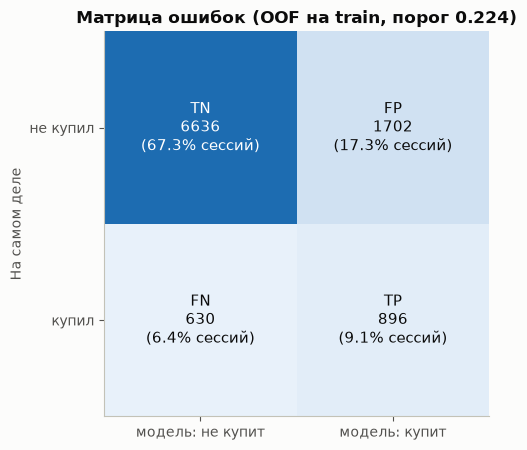

Отмечено моделью: 2598 сессий, из них не купили (FP): 65.5%
FP на каждого угаданного покупателя: 1.90
FP среди всех, кто не купил: 20.4%


In [2]:
counts = train["group"].value_counts()
cm = np.array([[counts["TN"], counts["FP"]], [counts["FN"], counts["TP"]]])

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.imshow(cm, cmap=SEQ_CMAP, vmin=0, vmax=cm.max() * 1.3)
cell_names = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cell_names[i][j]}\n{cm[i, j]}\n({cm[i, j] / cm.sum():.1%} сессий)",
                ha="center", va="center", fontsize=11,
                color="white" if cm[i, j] > cm.max() * 0.6 else "#0b0b0b")
ax.set_xticks([0, 1])
ax.set_xticklabels(["модель: не купит", "модель: купит"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["не купил", "купил"])
ax.set_ylabel("На самом деле")
ax.grid(False)
ax.set_title(f"Матрица ошибок (OOF на train, порог {THRESHOLD:.3f})")
save_fig(fig, "06_confusion_matrix")
plt.show()

print(f"Отмечено моделью: {counts['TP'] + counts['FP']} сессий, из них не купили (FP): "
      f"{counts['FP'] / (counts['TP'] + counts['FP']):.1%}")
print(f"FP на каждого угаданного покупателя: {counts['FP'] / counts['TP']:.2f}")
print(f"FP среди всех, кто не купил: {counts['FP'] / (counts['FP'] + counts['TN']):.1%}")

**Что увидел.** Модель отметила 2598 сессий: 896 из них купили (TP), 1702 не купили (FP). На каждого угаданного покупателя приходится 1.9 "ложной тревоги". 1702 сессии FP составляют 17.3% всех сессий train и 20.4% всех, кто ушёл без покупки. Пропущено 630 покупателей (FN).

**Что это значит.** Ложноположительных много, почти вдвое больше, чем угаданных покупателей. Вопрос: это шум модели (случайные люди, которых она зря отметила) или осмысленная группа, которая действительно ведёт себя как покупатели? Ответ даёт сравнение профилей.

## 2. Профиль: чем FP похожи на покупателей и чем отличаются от обычных ушедших

**Что хочу проверить.** Сравниваю четыре группы по поведению. Использую и новые признаки из 04: они не помогли модели, но удобны для описания ("сколько секунд на карточку товара"). Для числовых признаков беру медианы, для категориальных доли.

Отдельно смотрю на `PageValues`. Модель его **не видит**, поэтому он полезен как "внешний свидетель": если FP и TP различаются по нему, это различие модель уловить не могла.

In [3]:
profile_num = (train.groupby("group")[[
    "p", "ProductRelated", "ProductRelated_Duration", "avg_product_time", "Administrative",
    "total_duration", "BounceRates", "ExitRates"]].median().T[GROUP_ORDER])
profile_num.loc["ProductRelated_Duration"] /= 60
profile_num.loc["total_duration"] /= 60
profile_num.index = [
    "оценка модели (медиана)", "товарных страниц", "минут на товарных страницах",
    "секунд на одну товарную страницу", "служебных страниц", "минут за весь визит",
    "показатель отказов", "показатель выхода"]

profile_share = train.groupby("group").agg(**{
    "доля новых посетителей": ("VisitorType", lambda s: (s == "New_Visitor").mean()),
    "доля заходивших на служебные страницы": ("visited_admin", "mean"),
    "доля визитов в ноябре": ("Month", lambda s: (s == "Nov").mean()),
    "доля визитов в мае": ("Month", lambda s: (s == "May").mean()),
    "доля визитов в выходные": ("Weekend", "mean"),
    "доля визитов рядом с праздником": ("SpecialDay", lambda s: (s > 0).mean()),
    "доля из источника трафика 2": ("TrafficType", lambda s: (s == 2).mean()),
    "доля с PageValues > 0 (модель не видит)": ("PageValues", lambda s: (s > 0).mean()),
}).T[GROUP_ORDER]

profile = pd.concat([profile_num, profile_share])
profile.loc["сессий в группе"] = counts[GROUP_ORDER].values
profile.columns = [f"{g}: {GROUP_NAMES[g]}" for g in GROUP_ORDER]
profile.round(3)

,"TN: не купили, модель так и думала","FP: не купили, модель ждала покупку","TP: купили, модель угадала","FN: купили, модель пропустила"
оценка модели (медиана),0.084,0.289,0.326,0.156
товарных страниц,12.000,33.000,35.000,19.000
минут на товарных страницах,5.647,21.464,23.753,11.321
секунд на одну товарную страницу,24.370,37.316,38.471,32.136
служебных страниц,0.000,3.000,3.000,2.000
минут за весь визит,6.808,24.844,27.238,12.933
показатель отказов,0.008,0.000,0.000,0.003
показатель выхода,0.036,0.013,0.012,0.024
доля новых посетителей,0.086,0.261,0.290,0.116
доля заходивших на служебные страницы,0.418,0.798,0.783,0.670


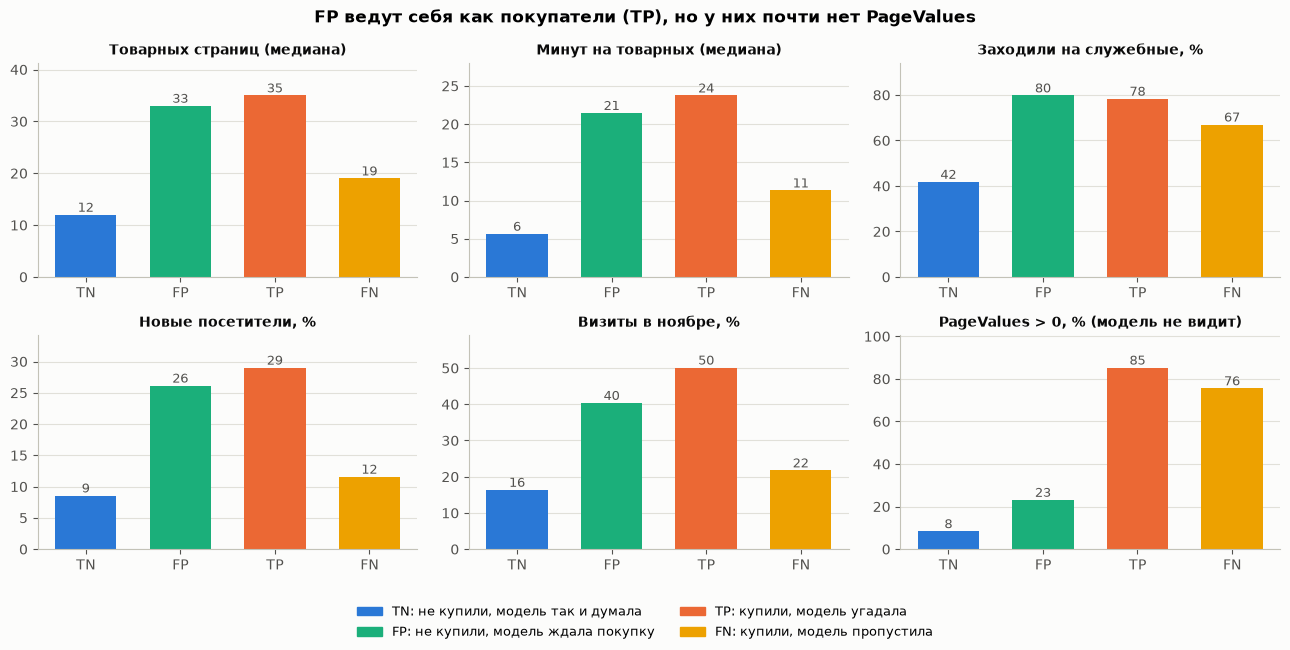

In [4]:
panels = [
    ("ProductRelated", "median", "Товарных страниц (медиана)", 1),
    ("ProductRelated_Duration", "median", "Минут на товарных (медиана)", 1 / 60),
    ("visited_admin", "mean", "Заходили на служебные, %", 100),
    ("VisitorType", lambda s: (s == "New_Visitor").mean(), "Новые посетители, %", 100),
    ("Month", lambda s: (s == "Nov").mean(), "Визиты в ноябре, %", 100),
    ("PageValues", lambda s: (s > 0).mean(), "PageValues > 0, % (модель не видит)", 100),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, func, title, scale) in zip(axes.ravel(), panels):
    values = train.groupby("group")[col].agg(func)[GROUP_ORDER] * scale
    ax.bar(range(4), values, color=[GROUP_COLORS[g] for g in GROUP_ORDER], width=0.65)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.0f}", ha="center", va="bottom", color=INK_2, fontsize=9)
    ax.set_xticks(range(4))
    ax.set_xticklabels(GROUP_ORDER)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="x", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER]
fig.legend(handles, [f"{g}: {GROUP_NAMES[g]}" for g in GROUP_ORDER], loc="lower center",
           ncol=2, fontsize=9)
fig.suptitle("FP ведут себя как покупатели (TP), но у них почти нет PageValues", fontweight="bold")
fig.tight_layout(rect=(0, 0.09, 1, 1))
save_fig(fig, "06_segment_profile")
plt.show()

**Что увидел.**
- **По поведению FP почти не отличаются от покупателей (TP):** 33 товарные страницы против 35, 21.5 минуты на товарных против 23.8, 37 секунд на одну товарную страницу против 38, на служебные страницы заходили 80% против 78%. Показатель выхода у обеих групп около 0.012-0.013.
- **От обычных ушедших (TN) FP отличаются сильно:** у TN медиана 12 товарных страниц и 5.6 минуты, на служебные заходят 42%.
- **Время и тип визита:** 40.4% FP пришлись на ноябрь (у TP 50.1%, у TN 16.4%), новых посетителей 26.1% (у TP 29.0%, у TN 8.6%).
- **Единственное резкое различие FP и TP в `PageValues`:** больше нуля у 85.3% покупателей и лишь у 23.1% FP.

**Что это значит.** FP не шум модели. Это осмысленная группа, которая **по всем видимым поведенческим признакам ведёт себя как покупатели**, но уходит без покупки. Модель не может отличить их от покупателей, потому что в её признаках разницы почти нет.

Разницу показывает только `PageValues`, признак, который "знает" о покупке (см. 04). Это ещё одно подтверждение утечки: признак различает группы, которые по поведению одинаковы. Скорее всего, причина ухода FP лежит в том, чего нет в данных: цена, доставка, наличие размера, сравнение с другими магазинами.

## 3. Сегмент "почти-покупатели"

**Название:** "Почти-покупатели" (выбирали, но не купили).

**Описание простыми словами.** Это посетители, которые ведут себя как будущие покупатели. Они долго и внимательно смотрят товары: медиана 33 товарные страницы и больше 20 минут, около 37 секунд на карточку. Чаще всего заходят в личный кабинет или на другие служебные страницы (80%) и ходят по страницам, после которых на сайте обычно остаются. Но уходят без покупки. Сегмент заметно "сезонный": 40% таких визитов приходятся на ноябрь, когда конверсия в целом самая высокая. Новых посетителей среди них в 3 раза больше, чем среди обычных ушедших.

**Размер.** По OOF на train это 1702 сессии, или 17.3% всех визитов и 20.4% всех, кто ушёл без покупки. На каждого покупателя, которого модель находит, приходится 1.9 "почти-покупателя".

In [5]:
# Сегмент зависит от порога: насколько он меняется при более строгом пороге
rows = []
for t in [THRESHOLD, 0.3, 0.4, 0.5]:
    flagged = train["p"] >= t
    fp = (flagged & (train[TARGET] == 0)).sum()
    tp = (flagged & (train[TARGET] == 1)).sum()
    rows.append({"порог": round(t, 3), "почти-покупателей (FP)": fp, "покупателей среди отмеченных (TP)": tp,
                 "доля FP среди всех сессий": fp / len(train),
                 "конверсия среди отмеченных": tp / (tp + fp)})
pd.DataFrame(rows).set_index("порог").round(3)

,почти-покупателей (FP),покупателей среди отмеченных (TP),доля FP среди всех сессий,конверсия среди отмеченных
порог,,,,
0.224,1702,896,0.173,0.345
0.300,745,547,0.076,0.423
0.400,248,257,0.025,0.509
0.500,48,59,0.005,0.551


**Что увидел.** При пороге 0.3 "почти-покупателей" 745, при 0.4 их 248, при 0.5 всего 48. Чем строже порог, тем выше конверсия среди отмеченных (от 34.5% до 55.1%), но тем меньше сегмент.

**Что это значит.** Граница сегмента условная. "Ядро" составляют около 250 сессий с оценкой выше 0.4, среди таких визитов покупает примерно каждый второй. Широкий вариант даёт около 1700 сессий при пороге 0.224. Какой брать, зависит от того, что с ним делать. Для дешёвых действий (напоминание) подойдёт широкий, для дорогих (скидка) разумнее узкий. Это и считаю в 07.

## 4. Обратная ошибка: кого модель пропускает (FN)

**Что хочу проверить.** Кто те 630 покупателей, которых модель не ждала.

In [6]:
fn_vs = profile.loc[["товарных страниц", "минут на товарных страницах", "доля новых посетителей",
                     "доля визитов в мае", "доля визитов в ноябре", "доля с PageValues > 0 (модель не видит)"]]
fn_vs.round(3)

,"TN: не купили, модель так и думала","FP: не купили, модель ждала покупку","TP: купили, модель угадала","FN: купили, модель пропустила"
товарных страниц,12.000,33.000,35.000,19.000
минут на товарных страницах,5.647,21.464,23.753,11.321
доля новых посетителей,0.086,0.261,0.290,0.116
доля визитов в мае,0.321,0.165,0.156,0.241
доля визитов в ноябре,0.164,0.404,0.501,0.217
доля с PageValues > 0 (модель не видит),0.084,0.231,0.853,0.756


**Что увидел.** Пропущенные покупатели смотрят заметно меньше: 19 товарных страниц против 35 у угаданных, 11.3 минуты против 23.8. Среди них мало новых посетителей (11.6% против 29.0%), больше майских визитов (24.1% против 15.6%) и меньше ноябрьских (21.7% против 50.1%). При этом `PageValues > 0` у 75.6%.

**Что это значит.** Это "быстрые покупатели", в основном вернувшиеся посетители, которые, похоже, знают, что хотят, и покупают без долгого выбора. Для промокода эта ошибка не страшна: им скидка и не нужна.

## 5. Проверка на тесте

**Что хочу проверить.** Сохраняется ли профиль сегмента на данных, которые не участвовали ни в обучении, ни в анализе выше. Использую предсказания финальной модели на тесте из ноутбука 05, порог тот же.

In [7]:
test = add_behavior_features(load_test())
test["p"] = pd.read_csv(TEST_PRED_PATH, index_col="row_id")["p"]
test = label_groups(test, "p")

test_profile = pd.concat([
    test.groupby("group")[["ProductRelated", "ProductRelated_Duration", "avg_product_time"]].median().T,
    test.groupby("group").agg(**{
        "visited_admin": ("visited_admin", "mean"),
        "new_visitor": ("VisitorType", lambda s: (s == "New_Visitor").mean()),
        "november": ("Month", lambda s: (s == "Nov").mean()),
        "page_values_pos": ("PageValues", lambda s: (s > 0).mean()),
    }).T,
])[GROUP_ORDER]
test_profile.loc["ProductRelated_Duration"] /= 60
test_profile.index = ["товарных страниц", "минут на товарных страницах", "секунд на одну товарную страницу",
                      "доля заходивших на служебные страницы", "доля новых посетителей",
                      "доля визитов в ноябре", "доля с PageValues > 0 (модель не видит)"]
test_profile.loc["сессий в группе"] = test["group"].value_counts()[GROUP_ORDER].values
test_profile.round(3)

group,TN,FP,TP,FN
товарных страниц,13.000,36.000,42.000,20.000
минут на товарных страницах,5.878,21.369,25.473,11.139
секунд на одну товарную страницу,25.492,34.511,37.546,30.203
доля заходивших на служебные страницы,0.419,0.791,0.727,0.684
доля новых посетителей,0.086,0.266,0.302,0.153
доля визитов в ноябре,0.173,0.411,0.600,0.288
доля с PageValues > 0 (модель не видит),0.090,0.209,0.815,0.740
сессий в группе,1648.000,436.000,205.000,177.000


**Что увидел.** На тесте 436 FP и 205 TP. FP снова похожи на покупателей: 36 товарных страниц против 42, 21.4 минуты против 25.5, на служебные страницы заходили 79% против 73%. От обычных ушедших (13 страниц, 5.9 минуты, 42%) они так же далеки. `PageValues > 0` у 20.9% FP и 81.5% TP. Отличие от train: в тесте у TP больше ноябрьских визитов (60.0% против 50.1%), но для 205 сессий это в пределах случайных колебаний.

**Что это значит.** Профиль сегмента устойчив: на новых данных "почти-покупатели" выглядят так же.

## 6. Что бизнес может делать с сегментом

Все пункты ниже являются **гипотезами**. Данные показывают, что эти люди ведут себя как покупатели, но не говорят, *почему* они не купили и что их вернёт. Каждую идею нужно проверять экспериментом.

1. **Предложение при уходе.** Показывать скидку или бесплатную доставку, когда "тёплый" по оценке модели посетитель собирается закрыть вкладку. Главный риск в том, что часть получивших предложение купила бы и так. Выгодно ли это, считаю в 07.
2. **Напоминание.** 80% "почти-покупателей" заходили на служебные страницы. Если среди них много авторизованных, им можно отправить письмо или пуш с просмотренными товарами (при наличии согласия на рассылку). Это дешевле скидки.
3. **Разбор воронки оформления.** Раз человек дошёл до служебных страниц и ушёл, стоит проверить, нет ли там препятствий: обязательная регистрация, стоимость доставки, которая видна только в конце, мало способов оплаты. Это проверяется не моделью, а UX-аудитом и анализом логов.
4. **Ноябрь.** 40% сегмента приходится на ноябрь. Возможно, в сезон распродаж люди сравнивают цены в нескольких магазинах или ждут скидок. Тогда помогут гарантия лучшей цены или подписка на уведомление о снижении цены.

## 7. Ограничения определения сегмента

- **Сегмент задан моделью и порогом.** При другом пороге или другой модели состав изменится: от 48 до 1702 сессий при порогах от 0.5 до 0.224.
- **Это не "брошенные корзины".** Событий корзины в данных нет. Нельзя утверждать, что эти люди что-то положили в корзину. Можно сказать только, что они вели себя похоже на покупателей.
- **Не видно, что было потом.** У сессий нет ID пользователя. Часть "почти-покупателей" могла купить в следующем визите. Тогда это не потерянные клиенты, а люди, которые выбирают в несколько заходов, и скидка для них чистая потеря.
- **Признаки посчитаны по всей сессии.** В реальности, чтобы что-то предложить человеку, его надо распознать *до* ухода, на неполной сессии. Тогда отличить его будет труднее.
- **Длительности занижены** (время последней страницы не записывается, см. 01), так что "минуты на сайте" приблизительные.

## Итоги

- Модель (порог 0.224) отмечает 2598 сессий train, из них **1702 ложноположительные**: 1.9 на каждого угаданного покупателя, 17.3% всех визитов.
- **"Почти-покупатели" (FP) по поведению почти не отличаются от покупателей:** 33 товарные страницы против 35, 21.5 минуты против 23.8, 80% против 78% заходили на служебные страницы. От обычных ушедших отличаются в 2-3 раза.
- Единственное резкое отличие от покупателей: **`PageValues > 0` у 23% против 85%**. Это признак, который модель не видит и который, вероятно, содержит саму покупку.
- Сегмент сезонный: **40% визитов приходится на ноябрь**. Новых посетителей 26% против 9% среди обычных ушедших.
- **Пропущенные покупатели (FN) "быстрые":** 19 страниц, 11 минут, в основном вернувшиеся посетители. На тесте профиль сегмента повторяется.

## Что не получилось или удивило

- Я ожидал найти внутри FP "случайных" людей, которых модель отметила зря. Вместо этого вся группа оказалась очень однородной и очень похожей на покупателей. Значит, улучшать модель на этих признаках особо некуда: по ним покупку от не-покупки здесь не отличить.
- Без событий корзины и ID пользователя нельзя проверить главное: почему они ушли и вернулись ли потом.

## Новые идеи

- Если бы у магазина были события корзины, сегмент можно было бы разделить на "положил в корзину и ушёл" и "долго смотрел, но в корзину ничего не клал". Это разные проблемы с разными решениями.
- Для сегмента полезнее модель *отклика на промокод* (uplift-модель), чем модель вероятности покупки. Для неё нужны данные эксперимента, об этом в 07.

## Следующие шаги

- **В ноутбуке 07** сделаю бизнес-симуляцию: выгодно ли давать промокод "почти-покупателям" по сравнению с "всем новым" и "никому", и при каких допущениях вывод меняется.
- **При большем времени:** кластеризация FP-сессий, чтобы проверить, нет ли внутри сегмента подгрупп; тот же анализ на датасете с событиями корзины.